# **Week 8 – Student Performance Visualization, Demographic Analysis & Educational Insights**

1. Import libraries and load the Week 7 dataset

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

In [2]:
df = pd.read_csv("/content/drive/MyDrive/EDA-Skill/student_performance_processed.csv")

print("Dataset loaded successfully!")
print("Shape:", df.shape)

df.head()

Dataset loaded successfully!
Shape: (1000, 13)


,gender,race_ethnicity,parental_level_of_education,lunch,test_preparation_course,math_score,reading_score,writing_score,total_score,average_score,percentage,pass_fail_status,performance_category
0,Female,Group B,Bachelor'S Degree,Standard,NaN,72,72,74,218,72.666667,72.666667,Pass,Good
1,Female,Group C,Some College,Standard,Completed,69,90,88,247,82.333333,82.333333,Pass,Very Good
2,Female,Group B,Master'S Degree,Standard,NaN,90,95,93,278,92.666667,92.666667,Pass,Excellent
3,Male,Group A,Associate'S Degree,Free/Reduced,NaN,47,57,44,148,49.333333,49.333333,Pass,Average
4,Male,Group C,Some College,Standard,NaN,76,78,75,229,76.333333,76.333333,Pass,Very Good


2. Understand the dataset

In [3]:
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nData Types:")
print(df.dtypes)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nStatistical Summary:")
display(df.describe())

Dataset Shape: (1000, 13)

Column Names:
['gender', 'race_ethnicity', 'parental_level_of_education', 'lunch', 'test_preparation_course', 'math_score', 'reading_score', 'writing_score', 'total_score', 'average_score', 'percentage', 'pass_fail_status', 'performance_category']

Data Types:
gender                          object
race_ethnicity                  object
parental_level_of_education     object
lunch                           object
test_preparation_course         object
math_score                       int64
reading_score                    int64
writing_score                    int64
total_score                      int64
average_score                  float64
percentage                     float64
pass_fail_status                object
performance_category            object
dtype: object

Missing Values:
gender                           0
race_ethnicity                   0
parental_level_of_education      0
lunch                            0
test_preparation_course        642

,math_score,reading_score,writing_score,total_score,average_score,percentage
count,1000.00000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000
mean,66.08900,69.169000,68.054000,203.312000,67.770667,67.770667
std,15.16308,14.600192,15.195657,42.771978,14.257326,14.257326
min,0.00000,17.000000,10.000000,27.000000,9.000000,9.000000
25%,57.00000,59.000000,57.750000,175.000000,58.333333,58.333333
50%,66.00000,70.000000,69.000000,205.000000,68.333333,68.333333
75%,77.00000,79.000000,79.000000,233.000000,77.666667,77.666667
max,100.00000,100.000000,100.000000,300.000000,100.000000,100.000000


In [4]:
categorical_columns = [
    "gender",
    "race_ethnicity",
    "parental_level_of_education",
    "lunch",
    "test_preparation_course"
]

for column in categorical_columns:
    if column in df.columns:
        print(f"\n{column}")
        print(df[column].value_counts())


gender
gender
Female    518
Male      482
Name: count, dtype: int64

race_ethnicity
race_ethnicity
Group C    319
Group D    262
Group B    190
Group E    140
Group A     89
Name: count, dtype: int64

parental_level_of_education
parental_level_of_education
Some College          226
Associate'S Degree    222
High School           196
Some High School      179
Bachelor'S Degree     118
Master'S Degree        59
Name: count, dtype: int64

lunch
lunch
Standard        645
Free/Reduced    355
Name: count, dtype: int64

test_preparation_course
test_preparation_course
Completed    358
Name: count, dtype: int64


3. Create group-wise average scores

In [5]:
score_columns = [
    "math_score",
    "reading_score",
    "writing_score"
]

group_columns = [
    "gender",
    "race_ethnicity",
    "parental_level_of_education",
    "lunch",
    "test_preparation_course"
]

for column in group_columns:
    if column in df.columns:
        print(f"\nAverage Scores by {column}")

        summary = df.groupby(column)[score_columns].mean().round(2)

        display(summary)


Average Scores by gender


,math_score,reading_score,writing_score
gender,,,
Female,63.63,72.61,72.47
Male,68.73,65.47,63.31



Average Scores by race_ethnicity


,math_score,reading_score,writing_score
race_ethnicity,,,
Group A,61.63,64.67,62.67
Group B,63.45,67.35,65.60
Group C,64.46,69.10,67.83
Group D,67.36,70.03,70.15
Group E,73.82,73.03,71.41



Average Scores by parental_level_of_education


,math_score,reading_score,writing_score
parental_level_of_education,,,
Associate'S Degree,67.88,70.93,69.90
Bachelor'S Degree,69.39,73.00,73.38
High School,62.14,64.70,62.45
Master'S Degree,69.75,75.37,75.68
Some College,67.13,69.46,68.84
Some High School,63.50,66.94,64.89



Average Scores by lunch


,math_score,reading_score,writing_score
lunch,,,
Free/Reduced,58.92,64.65,63.02
Standard,70.03,71.65,70.82



Average Scores by test_preparation_course


,math_score,reading_score,writing_score
test_preparation_course,,,
Completed,69.7,73.89,74.42


4. Gender-wise performance visualization

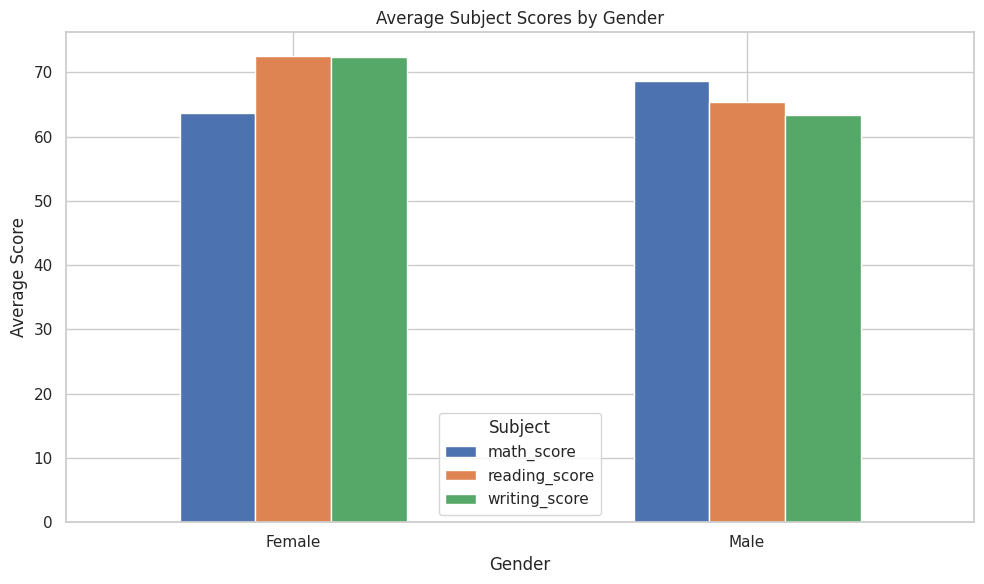

In [6]:
gender_summary = df.groupby("gender")[score_columns].mean()

gender_summary.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Average Subject Scores by Gender")
plt.xlabel("Gender")
plt.ylabel("Average Score")
plt.xticks(rotation=0)
plt.legend(title="Subject")
plt.tight_layout()
plt.show()

5. Performance by parental level of education

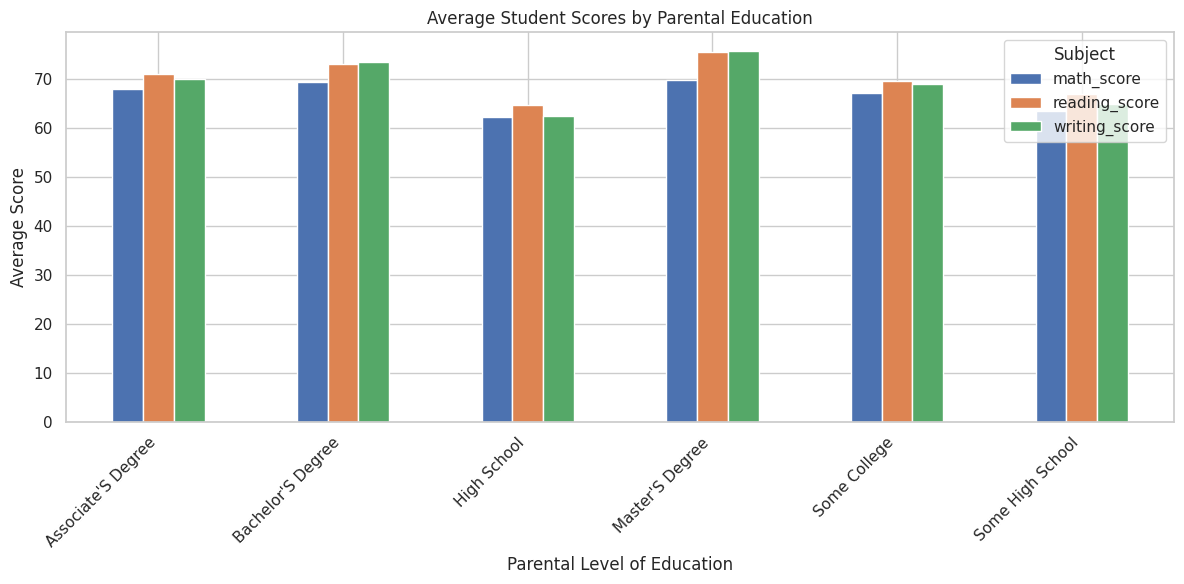

In [7]:
parent_education_summary = (
    df.groupby("parental_level_of_education")[score_columns]
    .mean()
)

parent_education_summary.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Average Student Scores by Parental Education")
plt.xlabel("Parental Level of Education")
plt.ylabel("Average Score")
plt.xticks(rotation=45, ha="right")
plt.legend(title="Subject")
plt.tight_layout()
plt.show()

6. Performance by lunch type

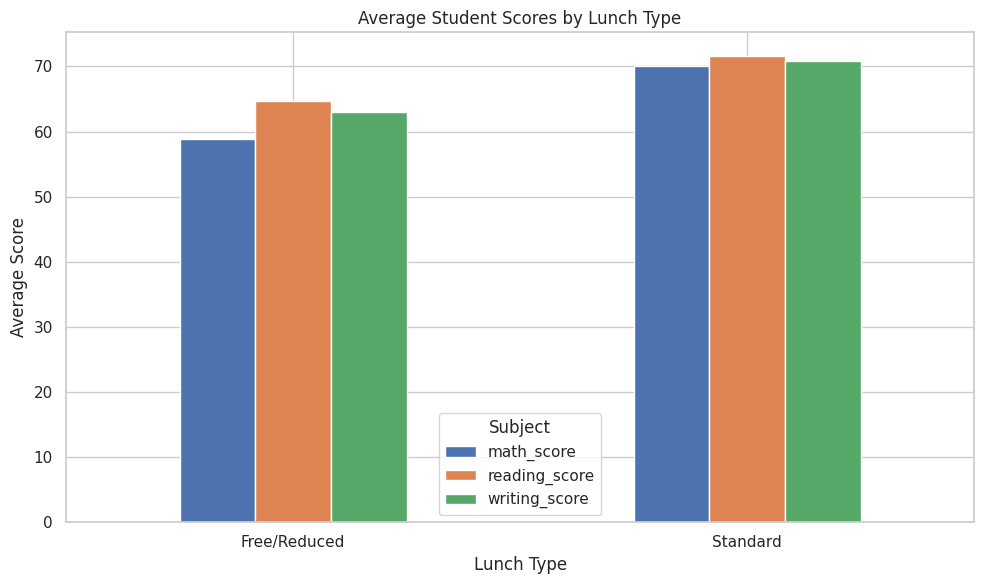

In [8]:
lunch_summary = df.groupby("lunch")[score_columns].mean()

lunch_summary.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Average Student Scores by Lunch Type")
plt.xlabel("Lunch Type")
plt.ylabel("Average Score")
plt.xticks(rotation=0)
plt.legend(title="Subject")
plt.tight_layout()
plt.show()

7. Test preparation course analysis

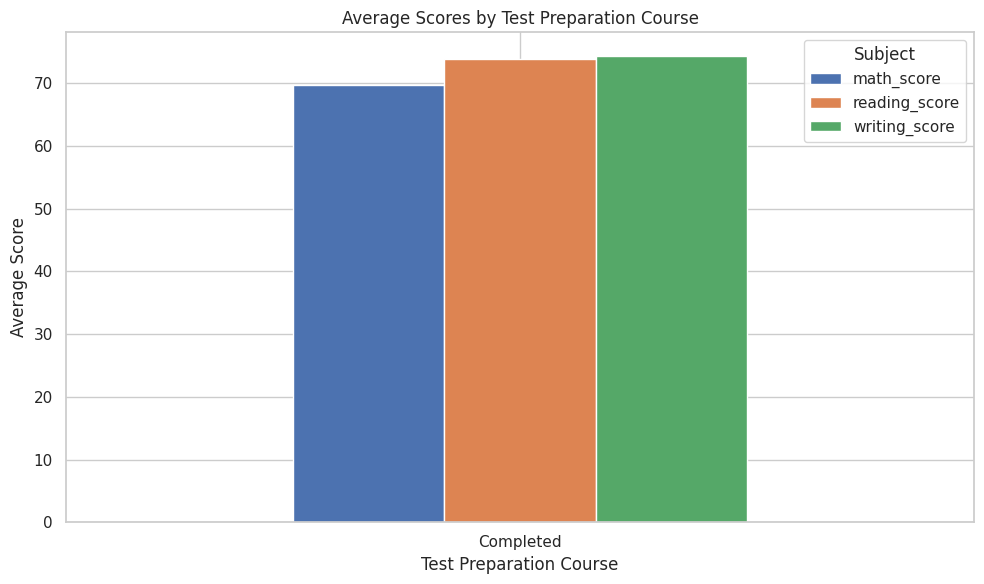

In [9]:
test_prep_summary = df.groupby("test_preparation_course")[score_columns].mean()

test_prep_summary.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Average Scores by Test Preparation Course")
plt.xlabel("Test Preparation Course")
plt.ylabel("Average Score")
plt.xticks(rotation=0)
plt.legend(title="Subject")
plt.tight_layout()
plt.show()

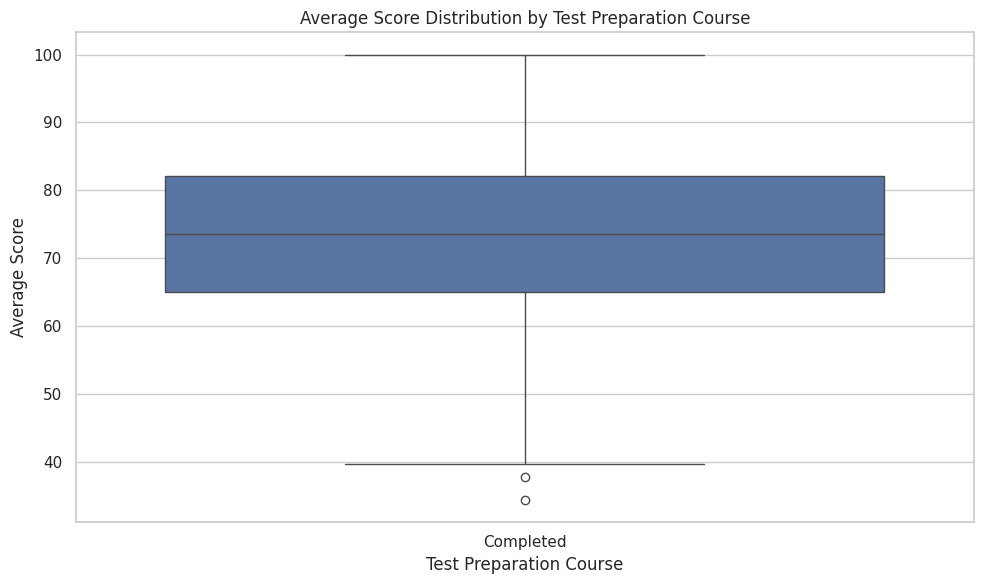

In [10]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x="test_preparation_course",
    y="average_score"
)

plt.title("Average Score Distribution by Test Preparation Course")
plt.xlabel("Test Preparation Course")
plt.ylabel("Average Score")

plt.tight_layout()
plt.show()

8. Race/Ethnicity-wise score analysis

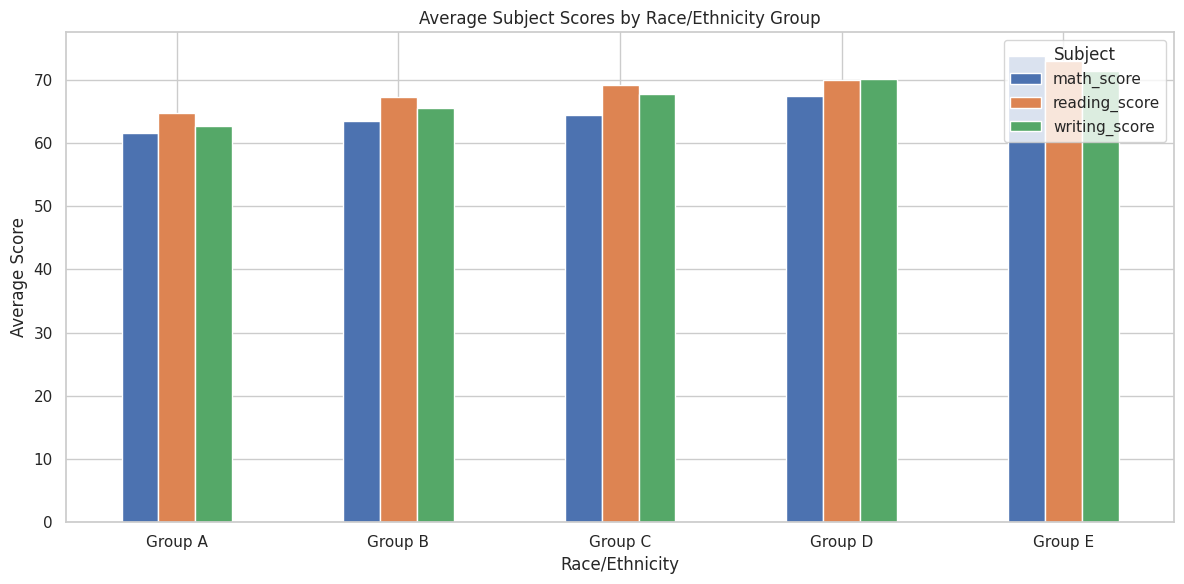

In [11]:
race_summary = df.groupby("race_ethnicity")[score_columns].mean()

race_summary.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Average Subject Scores by Race/Ethnicity Group")
plt.xlabel("Race/Ethnicity")
plt.ylabel("Average Score")
plt.xticks(rotation=0)
plt.legend(title="Subject")
plt.tight_layout()
plt.show()

9. Score distribution by demographic group

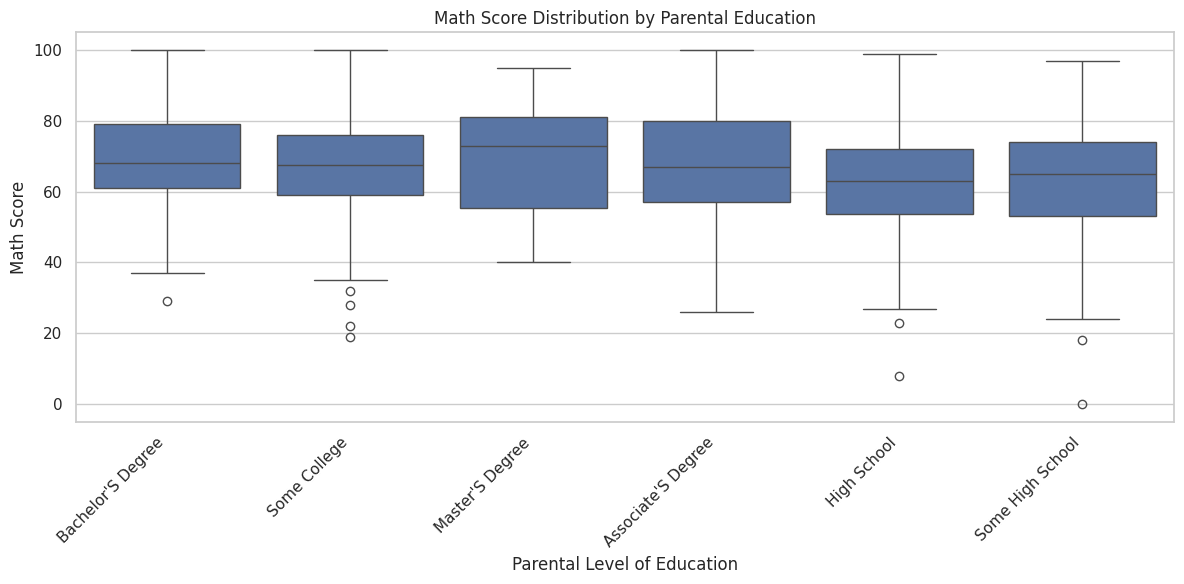

In [12]:
plt.figure(figsize=(12, 6))

sns.boxplot(
    data=df,
    x="parental_level_of_education",
    y="math_score"
)

plt.title("Math Score Distribution by Parental Education")
plt.xlabel("Parental Level of Education")
plt.ylabel("Math Score")
plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()

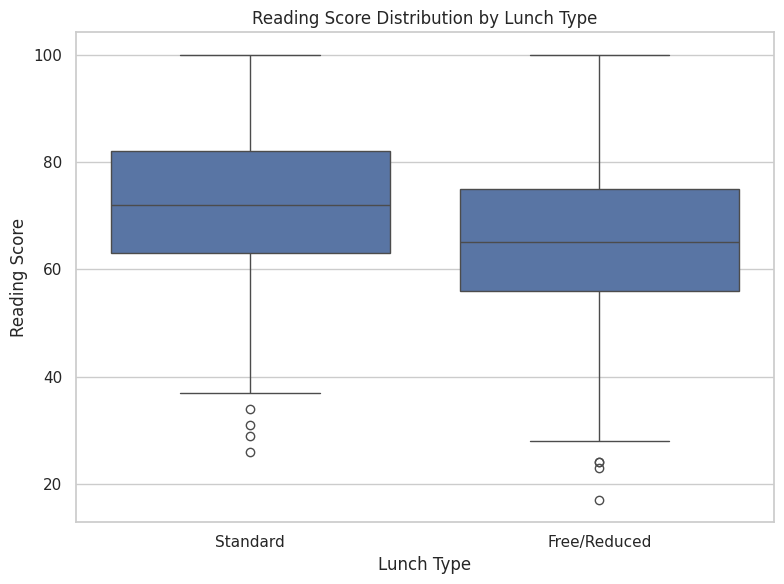

In [13]:
plt.figure(figsize=(8, 6))

sns.boxplot(
    data=df,
    x="lunch",
    y="reading_score"
)

plt.title("Reading Score Distribution by Lunch Type")
plt.xlabel("Lunch Type")
plt.ylabel("Reading Score")

plt.tight_layout()
plt.show()

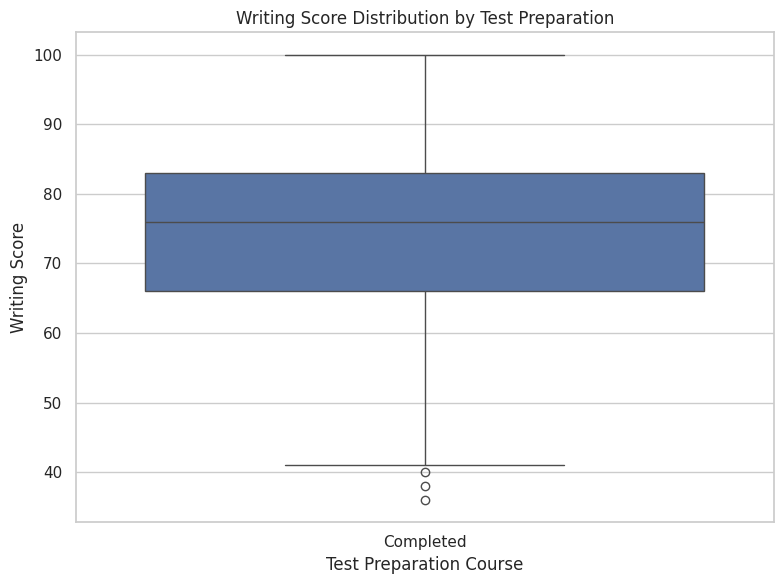

In [14]:
plt.figure(figsize=(8, 6))

sns.boxplot(
    data=df,
    x="test_preparation_course",
    y="writing_score"
)

plt.title("Writing Score Distribution by Test Preparation")
plt.xlabel("Test Preparation Course")
plt.ylabel("Writing Score")

plt.tight_layout()
plt.show()

10. Correlation analysis

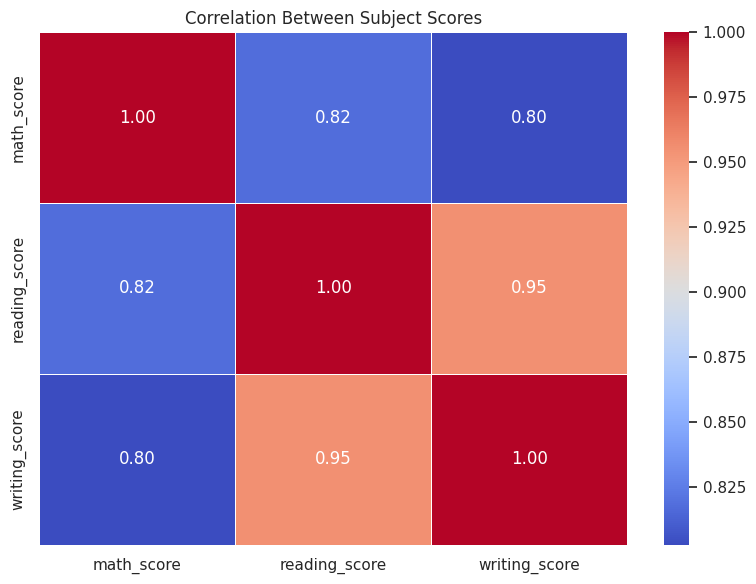

In [15]:
correlation_matrix = df[score_columns].corr()

plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Between Subject Scores")
plt.tight_layout()
plt.show()

11. Create a demographic comparison summary

In [16]:
demographic_summaries = {}

for column in group_columns:
    if column in df.columns:
        summary = (
            df.groupby(column)[score_columns + ["average_score"]]
            .agg(["mean", "median", "std", "count"])
            .round(2)
        )

        demographic_summaries[column] = summary

        print(f"\nSummary for {column}")
        display(summary)


Summary for gender


math_score                     reading_score                      \
             mean median    std count          mean median    std count   
gender                                                                    
Female      63.63   65.0  15.49   518         72.61   73.0  14.38   518   
Male        68.73   69.0  14.36   482         65.47   66.0  13.93   482   

       writing_score                     average_score                      
                mean median    std count          mean median    std count  
gender                                                                      
Female         72.47   74.0  14.84   518         69.57  70.33  14.54   518  
Male           63.31   64.0  14.11   482         65.84  66.33  13.70   482


Summary for race_ethnicity


math_score                     reading_score                \
                     mean median    std count          mean median    std   
race_ethnicity                                                              
Group A             61.63   61.0  14.52    89         64.67   64.0  15.54   
Group B             63.45   63.0  15.47   190         67.35   67.0  15.18   
Group C             64.46   65.0  14.85   319         69.10   71.0  14.00   
Group D             67.36   69.0  13.77   262         70.03   71.0  13.90   
Group E             73.82   74.5  15.53   140         73.03   74.0  14.87   

                     writing_score                     average_score         \
               count          mean median    std count          mean median   
race_ethnicity                                                                
Group A           89         62.67   62.0  15.47    89         62.99  61.33   
Group B          190         65.60   67.0  15.63   190         65.47  65.00   
Group C          319         67.83   68.0  14.98   319         67.13  68.33   
Group D          262         70.15   72.0  14.37   262         69.18  70.00   
Group E          140         71.41   72.0  15.11   140         72.75  73.50   

                             
                  std count  
race_ethnicity               
Group A         14.44    89  
Group B         14.73   190  
Group C         13.87   319  
Group D         13.25   262  
Group E         14.57   140


Summary for parental_level_of_education


math_score                     reading_score  \
                                  mean median    std count          mean   
parental_level_of_education                                                
Associate'S Degree               67.88   67.0  15.11   222         70.93   
Bachelor'S Degree                69.39   68.0  14.94   118         73.00   
High School                      62.14   63.0  14.54   196         64.70   
Master'S Degree                  69.75   73.0  15.15    59         75.37   
Some College                     67.13   67.5  14.31   226         69.46   
Some High School                 63.50   65.0  15.93   179         66.94   

                                                writing_score                \
                            median    std count          mean median    std   
parental_level_of_education                                                   
Associate'S Degree            72.5  13.87   222         69.90   70.5  14.31   
Bachelor'S Degree             73.0  14.29   118         73.38   74.0  14.73   
High School                   66.0  14.13   196         62.45   64.0  14.09   
Master'S Degree               76.0  13.78    59         75.68   75.0  13.73   
Some College                  70.5  14.06   226         68.84   70.0  15.01   
Some High School              67.0  15.48   179         64.89   66.0  15.74   

                                  average_score                      
                            count          mean median    std count  
parental_level_of_education                                          
Associate'S Degree            222         69.57  69.67  13.67   222  
Bachelor'S Degree             118         71.92  71.17  13.95   118  
High School                   196         63.10  65.00  13.51   196  
Master'S Degree                59         73.60  73.33  13.60    59  
Some College                  226         68.48  68.67  13.71   226  
Some High School              179         65.11  66.67  14.98   179


Summary for lunch


math_score                     reading_score                      \
                   mean median    std count          mean median    std count   
lunch                                                                           
Free/Reduced      58.92   60.0  15.16   355         64.65   65.0  14.90   355   
Standard          70.03   69.0  13.65   645         71.65   72.0  13.83   645   

             writing_score                     average_score                \
                      mean median    std count          mean median    std   
lunch                                                                        
Free/Reduced         63.02   64.0  15.43   355         62.20  62.67  14.46   
Standard             70.82   72.0  14.34   645         70.84  71.33  13.19   

                    
             count  
lunch               
Free/Reduced   355  
Standard       645


Summary for test_preparation_course


math_score                     reading_score         \
                              mean median    std count          mean median   
test_preparation_course                                                       
Completed                     69.7   69.0  14.44   358         73.89   75.0   

                                     writing_score                      \
                           std count          mean median    std count   
test_preparation_course                                                  
Completed                13.64   358         74.42   76.0  13.38   358   

                        average_score                      
                                 mean median    std count  
test_preparation_course                                    
Completed                       72.67   73.5  13.04   358

12. Generate key findings from the dataset

In [17]:
for column in group_columns:
    if column in df.columns:

        print(f"\nFindings for {column}")

        group_average = (
            df.groupby(column)["average_score"]
            .mean()
            .sort_values(ascending=False)
        )

        print("Highest average:", group_average.index[0])
        print("Highest score:", round(group_average.iloc[0], 2))

        print("Lowest average:", group_average.index[-1])
        print("Lowest score:", round(group_average.iloc[-1], 2))


Findings for gender
Highest average: Female
Highest score: 69.57
Lowest average: Male
Lowest score: 65.84

Findings for race_ethnicity
Highest average: Group E
Highest score: 72.75
Lowest average: Group A
Lowest score: 62.99

Findings for parental_level_of_education
Highest average: Master'S Degree
Highest score: 73.6
Lowest average: High School
Lowest score: 63.1

Findings for lunch
Highest average: Standard
Highest score: 70.84
Lowest average: Free/Reduced
Lowest score: 62.2

Findings for test_preparation_course
Highest average: Completed
Highest score: 72.67
Lowest average: Completed
Lowest score: 72.67


13. Export the analysis results

In [18]:
import os

os.makedirs("reports", exist_ok=True)

# Average scores by demographic and educational groups
for column in group_columns:
    if column in df.columns:

        summary = (
            df.groupby(column)[score_columns + ["average_score"]]
            .mean()
            .round(2)
        )

        summary.to_csv(
            f"reports/{column}_performance_summary.csv"
        )

# Correlation matrix
correlation_matrix.to_csv(
    "reports/subject_score_correlation.csv"
)

print("All summary reports exported successfully.")

All summary reports exported successfully.
